# Сердечно-сосудистые заболевания

Предсказываем метку `cardio` (`target` после подготовки данных) по данным NHANES.
Она отражает сообщённую участником историю сердечной недостаточности, ИБС, стенокардии, инфаркта или инсульта.
В датасете 28 270 наблюдений.

| Признаки | Значения |
|---|---|
| age, height, weight | Возраст в приблизительных днях (затем переводим в годы), рост в см, вес в кг |
| ap_hi, ap_lo | Систолическое и диастолическое давление, мм рт. ст. |
| gender | 1 - женский, 2 - мужской |
| cholesterol | Общий холестерин: 1 — <200, 2 — 200–<240, 3 — ≥240 мг/дл |
| gluc | HbA1c: 1 — <5.7%, 2 — 5.7–<6.5%, 3 — ≥6.5% |
| smoke, alco, active | Курение, употребление алкоголя, физическая активность: 0 / 1 |
| cardio | 1 — ответ «да» хотя бы на один из MCQ160B–F; 0 — «нет» на все пять |

Далее проверим пропуски, изучим распределения, сравним модели и подберём порог.


In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn import base, calibration, compose, ensemble, inspection, linear_model, metrics
from sklearn import model_selection, naive_bayes, neighbors, pipeline, preprocessing, svm

SEED = 42

## 1. EDA

Сначала проверим структуру, типы и диапазоны значений, затем рассмотрим пропуски и связь признаков с целевой меткой.


In [2]:
raw = pd.read_csv('../data/heart.csv', sep=';')
raw.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,62161,8036,2,172.3,69.2,111.0,75.0,1.0,1.0,0.0,NaN,0.0,0
1,62164,16071,1,170.1,67.2,118.0,60.0,1.0,1.0,0.0,NaN,1.0,0
2,62169,7670,2,164.8,54.6,125.0,78.0,1.0,1.0,0.0,1.0,0.0,0
3,62172,15706,1,172.0,98.6,102.0,71.0,1.0,1.0,1.0,1.0,0.0,0
4,62176,12418,1,171.6,68.7,107.0,69.0,1.0,1.0,0.0,1.0,1.0,0


In [3]:
raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28270 entries, 0 to 28269
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           28270 non-null  int64  
 1   age          28270 non-null  int64  
 2   gender       28270 non-null  int64  
 3   height       25624 non-null  float64
 4   weight       25588 non-null  float64
 5   ap_hi        24857 non-null  float64
 6   ap_lo        24857 non-null  float64
 7   cholesterol  24177 non-null  float64
 8   gluc         24680 non-null  float64
 9   smoke        28230 non-null  float64
 10  alco         17287 non-null  float64
 11  active       28252 non-null  float64
 12  cardio       28270 non-null  int64  
dtypes: float64(9), int64(4)
memory usage: 2.8 MB


In [4]:
raw.describe().round(2)

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
count,28270.00,28270.00,28270.00,25624.00,25588.00,24857.00,24857.00,24177.00,24680.00,28230.00,17287.00,28252.00,28270.0
mean,96767.89,17754.87,1.47,166.99,82.59,123.42,72.40,1.50,1.52,0.19,0.95,0.63,0.1
std,25456.51,6037.48,0.50,10.07,22.12,17.88,11.31,0.69,0.70,0.39,0.22,0.48,0.3
min,62161.00,7305.00,1.00,129.70,32.30,72.00,40.00,1.00,1.00,0.00,0.00,0.00,0.0
25%,77161.25,12418.00,1.00,159.60,67.00,111.00,65.00,1.00,1.00,0.00,1.00,0.00,0.0
50%,90281.50,17897.00,1.00,166.70,79.20,121.00,72.00,1.00,1.00,0.00,1.00,1.00,0.0
75%,130658.75,23011.00,2.00,174.20,94.30,133.00,79.00,2.00,2.00,0.00,1.00,1.00,0.0
max,142309.00,28855.00,2.00,204.50,198.90,234.00,142.00,3.00,3.00,1.00,1.00,1.00,1.0


In [5]:
pd.Series({
    'Пропуски': raw.isna().sum().sum(),
    'Дубли без id': raw.drop(columns='id').duplicated().sum(),
})

Пропуски        30878
Дубли без id     1843
dtype: int64

,Количество,"Доля, %"
alco,10983,38.85
cholesterol,4093,14.48
gluc,3590,12.70
ap_lo,3413,12.07
ap_hi,3413,12.07
weight,2682,9.49
height,2646,9.36
smoke,40,0.14
active,18,0.06


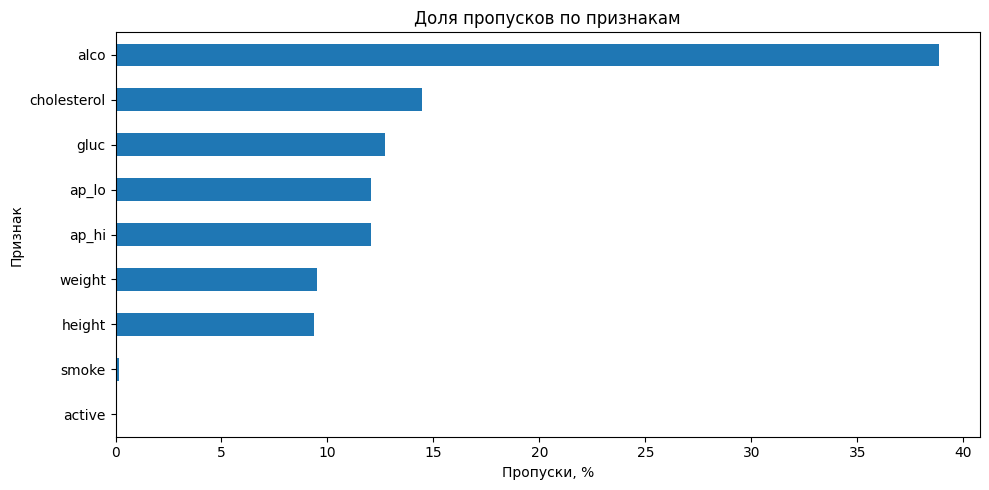

In [6]:
missing = pd.DataFrame({
    'Количество': raw.isna().sum(),
    'Доля, %': raw.isna().mean() * 100
})

missing = missing[missing['Количество'] > 0]
missing = missing.sort_values('Доля, %', ascending=False)

display(missing.round(2))

plt.figure(figsize=(10, 5))
missing['Доля, %'].sort_values().plot.barh()

plt.title('Доля пропусков по признакам')
plt.xlabel('Пропуски, %')
plt.ylabel('Признак')
plt.tight_layout()
plt.show()

Разделим данные примерно на 70% / 15% / 15%. При разделении группируем одинаковые строки без `id`, чтобы их копии не оказались в разных выборках.

Далее распределения по классам и связь с целевой меткой изучаем только на train (`eda`). Модель, набор признаков и порог выбираем на validation. Test используем для финальной оценки.


In [7]:
data = raw.drop(columns='id').rename(columns={'cardio': 'target'}).copy()
data['age'] /= 365.25

base_features = data.columns.drop('target').tolist()

In [8]:
def split_groups(frame, test_size):
    groups = pd.util.hash_pandas_object(
        frame.drop(columns='target'), index=False
    )
    splitter = model_selection.GroupShuffleSplit(
        n_splits=1, test_size=test_size, random_state=SEED
    )
    left, right = next(splitter.split(frame, groups=groups))
    return frame.iloc[left].copy(), frame.iloc[right].copy()


train, holdout = split_groups(data, 0.30)
validation, test = split_groups(holdout, 0.50)

eda = raw.loc[train.index]


In [9]:
def analyze_category(column):
    temp = eda[[column, 'cardio']].copy()
    temp[column] = temp[column].astype('Int64').astype('string').fillna('NaN')

    stats = temp.groupby(column)['cardio'].agg(
        count='size',
        rate='mean'
    )

    order = sorted([v for v in stats.index if v != 'NaN'], key=int)
    if 'NaN' in stats.index:
        order.append('NaN')

    stats = stats.loc[order]
    stats['Доля, %'] = stats['count'] / len(eda) * 100
    stats['cardio=1, %'] = stats['rate'] * 100

    display(stats[['count', 'Доля, %', 'cardio=1, %']].round(2))

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))

    stats['count'].plot.bar(ax=axes[0], rot=0)
    axes[0].set_title(f'{column}: распределение значений')
    axes[0].set_ylabel('Количество')

    stats['cardio=1, %'].plot.bar(ax=axes[1], rot=0)
    axes[1].set_title(f'{column}: доля cardio=1')
    axes[1].set_ylabel('Процент')

    plt.tight_layout()
    plt.show()

,count,"Доля, %","cardio=1, %"
alco,,,
0,613,3.11,11.42
1,11487,58.27,7.97
NaN,7615,38.63,12.62


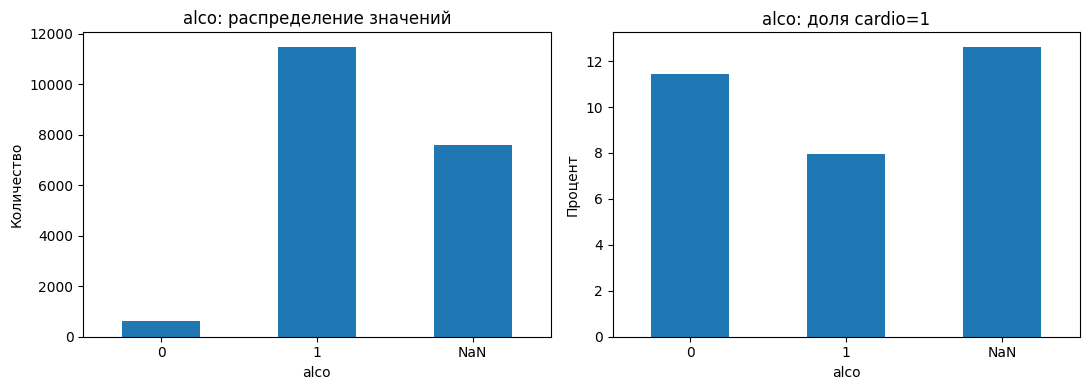

In [10]:
analyze_category('alco')

,count,"Доля, %","cardio=1, %"
cholesterol,,,
1,10488,53.20,11.74
2,4499,22.82,6.27
3,1932,9.80,7.25
NaN,2796,14.18,10.48


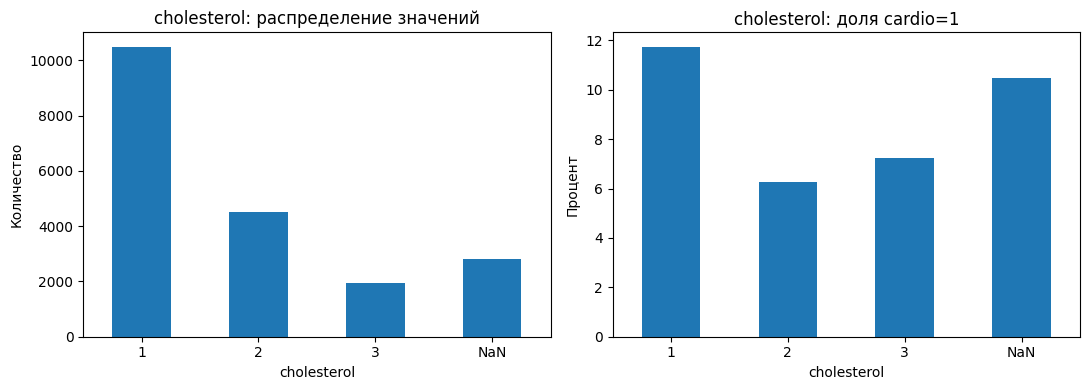

In [11]:
analyze_category('cholesterol')

,count,"Доля, %","cardio=1, %"
gluc,,,
1,10362,52.56,5.45
2,4735,24.02,13.14
3,2163,10.97,23.58
NaN,2455,12.45,10.14


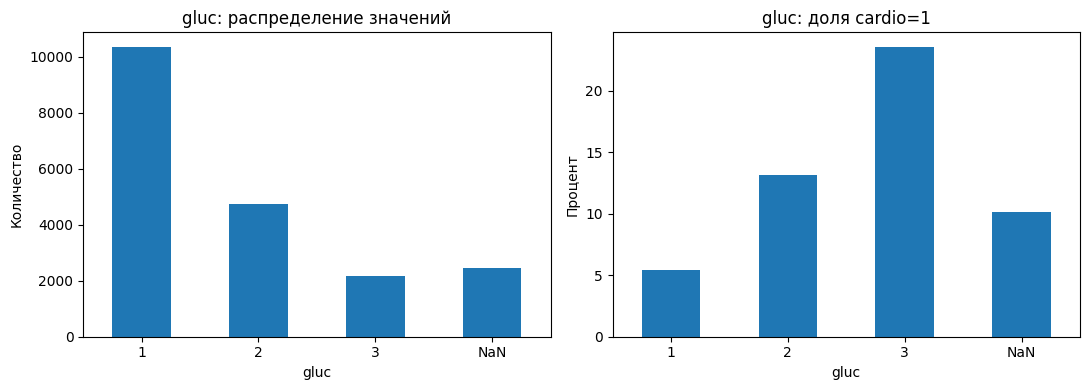

In [12]:
analyze_category('gluc')

,count,"Доля, %","cardio=1, %"
smoke,,,
0,15912,80.71,9.18
1,3776,19.15,12.82
NaN,27,0.14,7.41


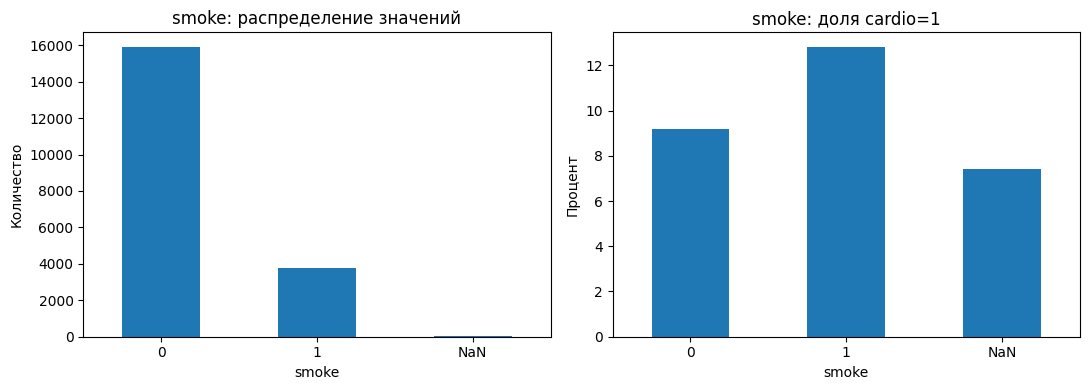

In [13]:
analyze_category('smoke')

,count,"Доля, %","cardio=1, %"
active,,,
0,7434,37.71,12.63
1,12270,62.24,8.21
NaN,11,0.06,0.00


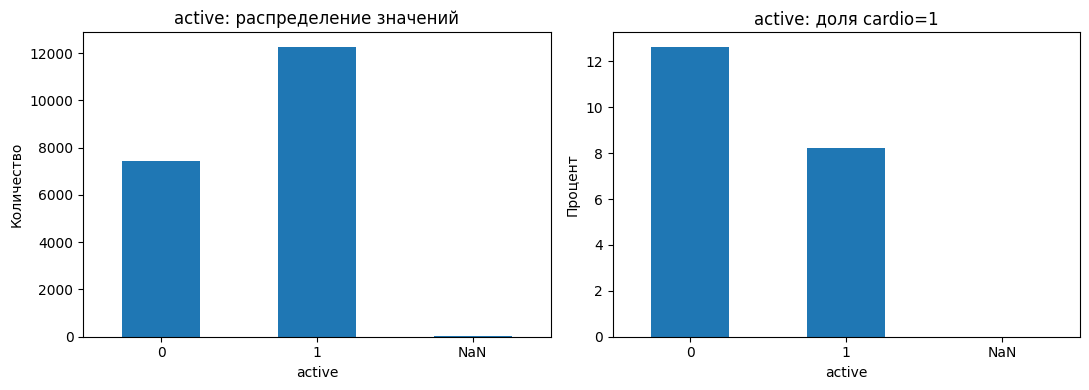

In [14]:
analyze_category('active')

In [15]:
def analyze_numeric(column):
    missing_mask = eda[column].isna()

    stats = eda.groupby(missing_mask)['cardio'].agg(
        count='size',
        rate='mean'
    )

    stats.index = stats.index.map({
        False: 'Есть значение',
        True: 'Пропуск'
    })
    stats['cardio=1, %'] = stats['rate'] * 100

    display(stats[['count', 'cardio=1, %']].round(2))

    display(
        eda.groupby('cardio')[column]
        .agg(['count', 'mean', 'median', 'std'])
        .round(2)
    )

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    sns.histplot(
        data=eda,
        x=column,
        hue='cardio',
        bins=30,
        stat='density',
        common_norm=False,
        element='step',
        fill=False,
        ax=axes[0]
    )
    axes[0].set_title(f'{column}: распределение по классам')

    missing_by_class = (
        missing_mask.groupby(eda['cardio']).mean() * 100
    )

    missing_by_class.plot.bar(ax=axes[1], rot=0)
    axes[1].set_title(f'{column}: пропуски по классам')
    axes[1].set_xlabel('cardio')
    axes[1].set_ylabel('Пропуски, %')

    plt.tight_layout()
    plt.show()

,count,"cardio=1, %"
height,,
Есть значение,17936,9.75
Пропуск,1779,11.13


,count,mean,median,std
cardio,,,,
0,16188,167.02,166.7,10.14
1,1748,166.95,167.1,9.95


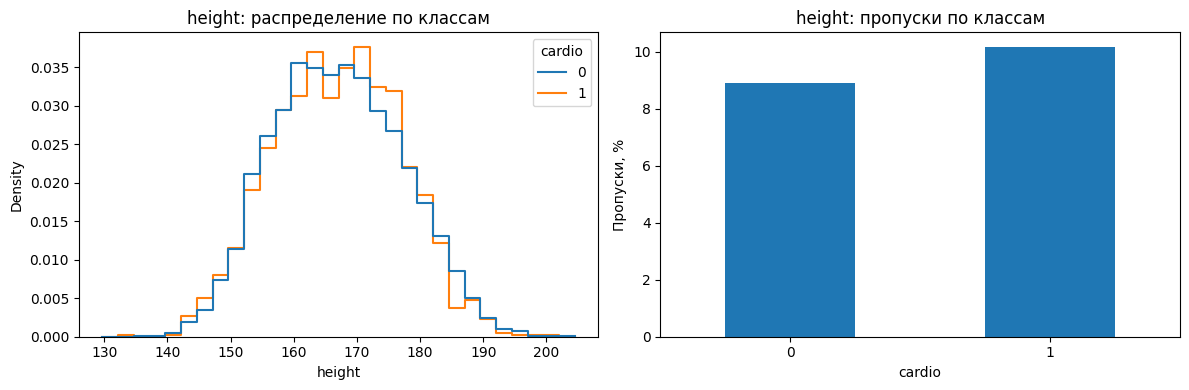

In [16]:
analyze_numeric('height')

,count,"cardio=1, %"
weight,,
Есть значение,17912,9.71
Пропуск,1803,11.43


,count,mean,median,std
cardio,,,,
0,16172,82.00,78.7,21.98
1,1740,87.67,83.5,23.27


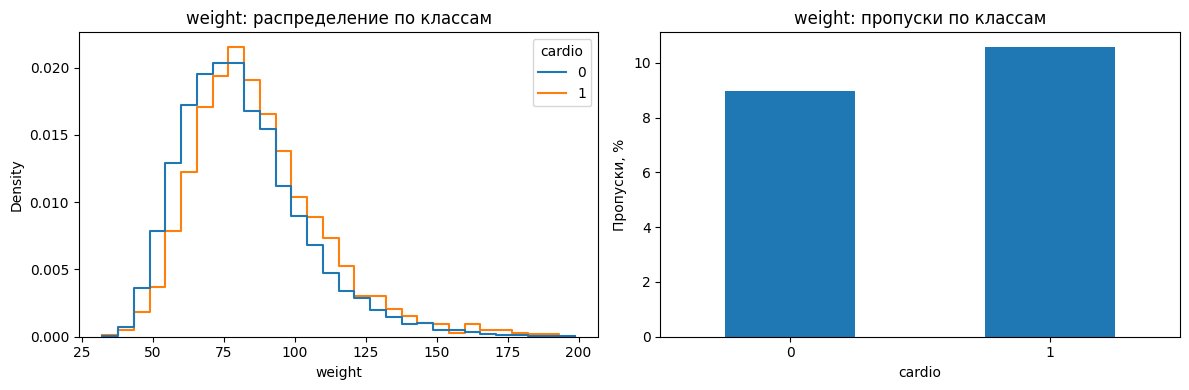

In [17]:
analyze_numeric('weight')

,count,"cardio=1, %"
ap_hi,,
Есть значение,17412,9.84
Пропуск,2303,10.07


,count,mean,median,std
cardio,,,,
0,15698,122.84,120.0,17.32
1,1714,130.19,128.0,20.99


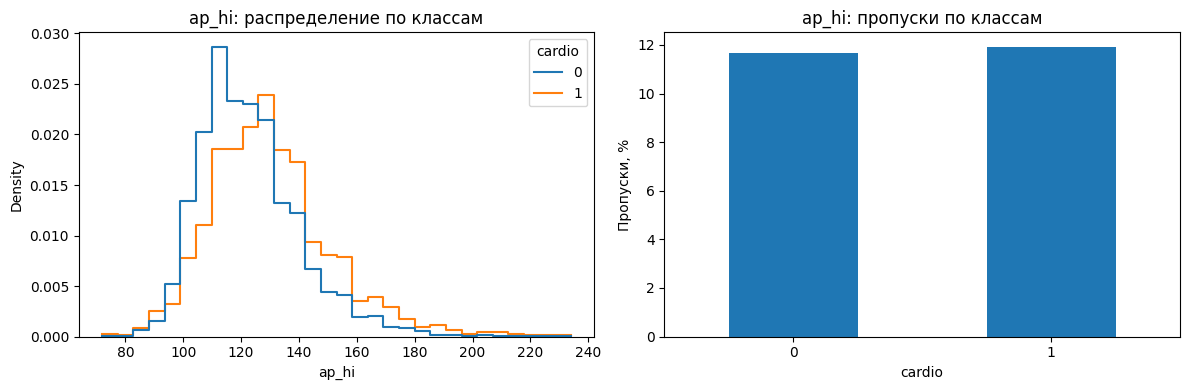

In [18]:
analyze_numeric('ap_hi')

,count,"cardio=1, %"
ap_lo,,
Есть значение,17412,9.84
Пропуск,2303,10.07


,count,mean,median,std
cardio,,,,
0,15698,72.58,72.0,11.15
1,1714,70.85,71.0,12.54


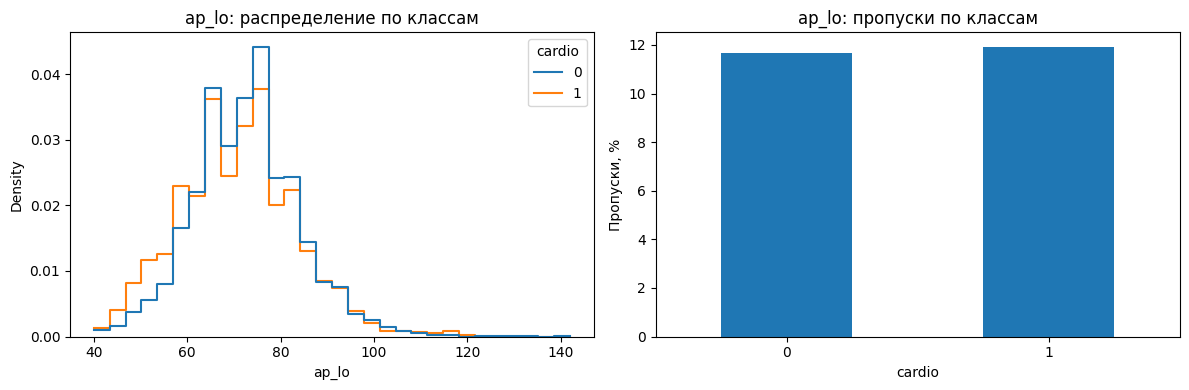

In [19]:
analyze_numeric('ap_lo')

В датасете 30 878 пропущенных значений и 1 843 дублирующиеся записи без учёта `id`. Наибольшая доля пропусков приходится на `alco` (38.85%), `cholesterol` (14.48%) и `gluc` (12.70%). Полное удаление строк с пропусками привело бы к существенной потере данных.

По распределениям на train видно, что наличие пропуска тоже может быть связано с целевой меткой: например, для `alco` доля `cardio=1` у пропущенных значений выше, чем у известного значения 1.

Для обработки выбрана следующая стратегия:

- `alco`, `cholesterol`, `gluc` - отдельная категория `-1` для неизвестного значения;
- `smoke`, `active` - заполнение модой;
- `height`, `weight`, `ap_hi`, `ap_lo` - заполнение медианой.

Медиану и моду считаем только по train и затем применяем к validation и test, чтобы избежать утечки данных.


In [20]:
num_fill = ['height', 'weight', 'ap_hi', 'ap_lo']
mode_fill = ['smoke', 'active']
unknown_fill = ['cholesterol', 'gluc', 'alco']

cat_cols = [
    'gender', 'cholesterol', 'gluc',
    'smoke', 'alco', 'active'
]

medians = train[num_fill].median()
modes = train[mode_fill].mode().iloc[0]

for frame in [train, validation, test]:
    frame[num_fill] = frame[num_fill].fillna(medians)
    frame[mode_fill] = frame[mode_fill].fillna(modes)
    frame[unknown_fill] = frame[unknown_fill].fillna(-1)

    frame[cat_cols] = frame[cat_cols].astype(int).astype(str)

Введём дополнительные признаки: ИМТ = вес / рост^2 (рост в метрах), пульсовое давление = `ap_hi - ap_lo`.

Сначала заполняем пропуски исходных признаков, затем рассчитываем новые. Рост, вес и оба давления **сохраняем**. ИМТ и пульсовое давление пока только кандидаты: для лидера сравним их по отдельности и вместе с базовым набором.


In [21]:
for frame in [train, validation, test]:
    frame['bmi'] = frame['weight'] / (frame['height'] / 100) ** 2
    frame['pulse_pressure'] = frame['ap_hi'] - frame['ap_lo']

numeric = [
    'age', 'height', 'weight',
    'ap_hi', 'ap_lo', 'bmi', 'pulse_pressure'
]

categorical = [
    'gender', 'cholesterol', 'gluc',
    'smoke', 'alco', 'active'
]

In [22]:
X_train, y_train = train.drop(columns='target'), train['target']
X_valid, y_valid = validation.drop(columns='target'), validation['target']
X_test, y_test = test.drop(columns='target'), test['target']

split_sizes = {
    'train': len(train),
    'validation': len(validation),
    'test': len(test)
}

display(pd.Series(split_sizes, name='Строк').to_frame())

pd.DataFrame({
    'Train': X_train.isna().sum(),
    'Validation': X_valid.isna().sum(),
    'Test': X_test.isna().sum()
})

,Строк
train,19715
validation,4263
test,4292


,Train,Validation,Test
age,0,0,0
gender,0,0,0
height,0,0,0
weight,0,0,0
ap_hi,0,0,0
ap_lo,0,0,0
cholesterol,0,0,0
gluc,0,0,0
smoke,0,0,0
alco,0,0,0


### Распределения и связь с классом

Посмотрим распределения числовых и категориальных признаков, долю `target=1` в категориях и корреляции. Графики строим по train после обработки пропусков.


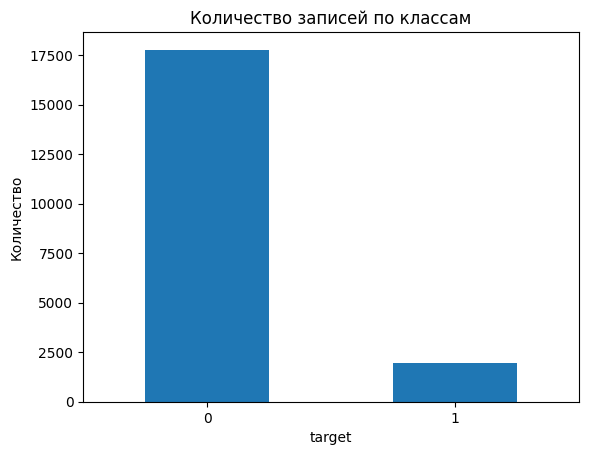

,Количество,"Доля, %"
target,,
0,17769,90.13
1,1946,9.87


In [23]:
counts = y_train.value_counts().sort_index()
percentages = y_train.value_counts(normalize=True).sort_index() * 100

ax = counts.plot.bar(
    title='Количество записей по классам',
    rot=0
)

plt.xlabel('target')
plt.ylabel('Количество')
plt.show()

display(pd.DataFrame({
    'Количество': counts,
    'Доля, %': percentages.round(2)
}))

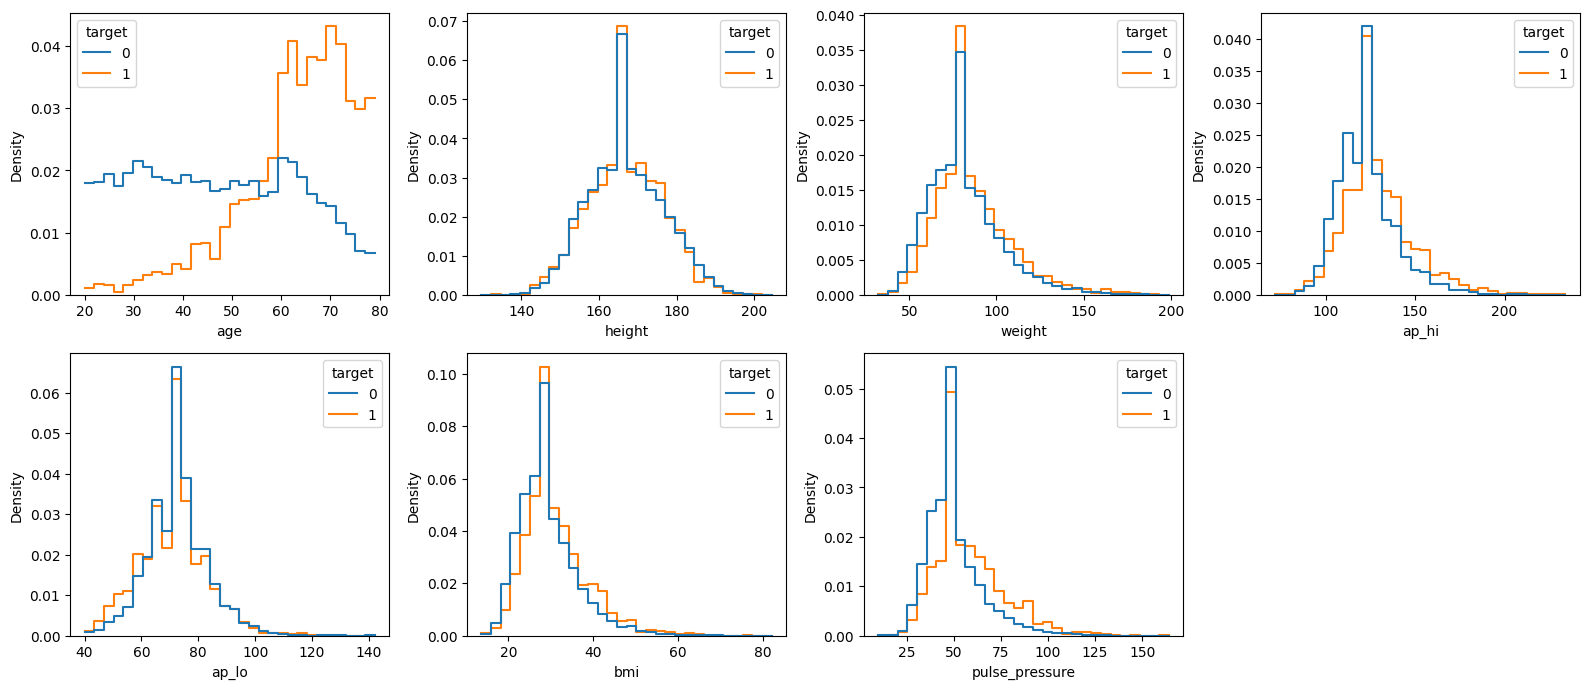

In [24]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, column in zip(axes.flat, numeric):
    sns.histplot(data=train, x=column, hue='target', bins=30, common_bins=True,
                 stat='density', common_norm=False, element='step', fill=False, ax=ax)
axes.flat[-1].remove()
plt.tight_layout()
plt.show()

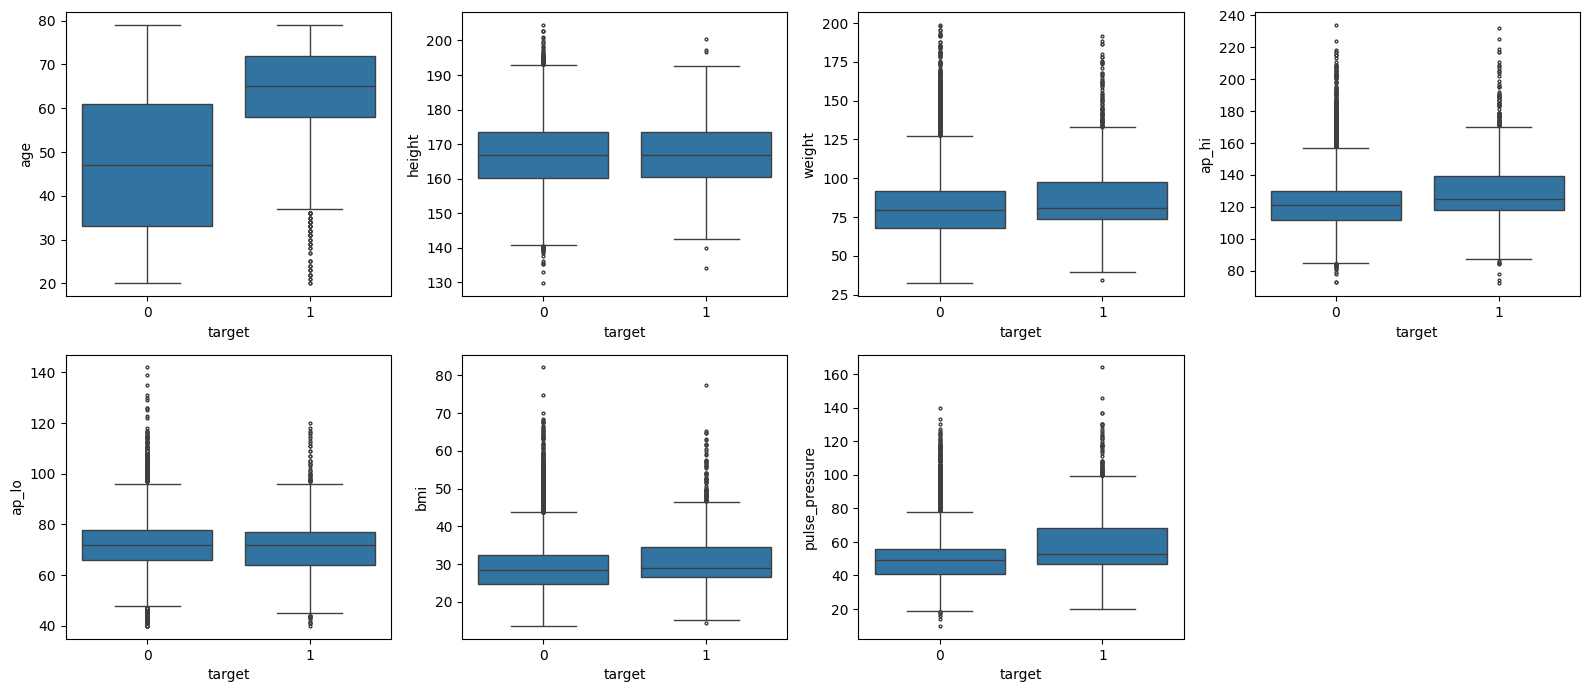

In [25]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, column in zip(axes.flat, numeric):
    sns.boxplot(data=train, x='target', y=column, showfliers=True, fliersize=2, ax=ax)
axes.flat[-1].remove()
plt.tight_layout()
plt.show()

In [26]:
train[categorical].apply(pd.Series.value_counts).fillna(0).astype(int)

,gender,cholesterol,gluc,smoke,alco,active
-1,0,2796,2455,0,7615,0
0,0,0,0,15939,613,7434
1,10239,10488,10362,3776,11487,12281
2,9476,4499,4735,0,0,0
3,0,1932,2163,0,0,0


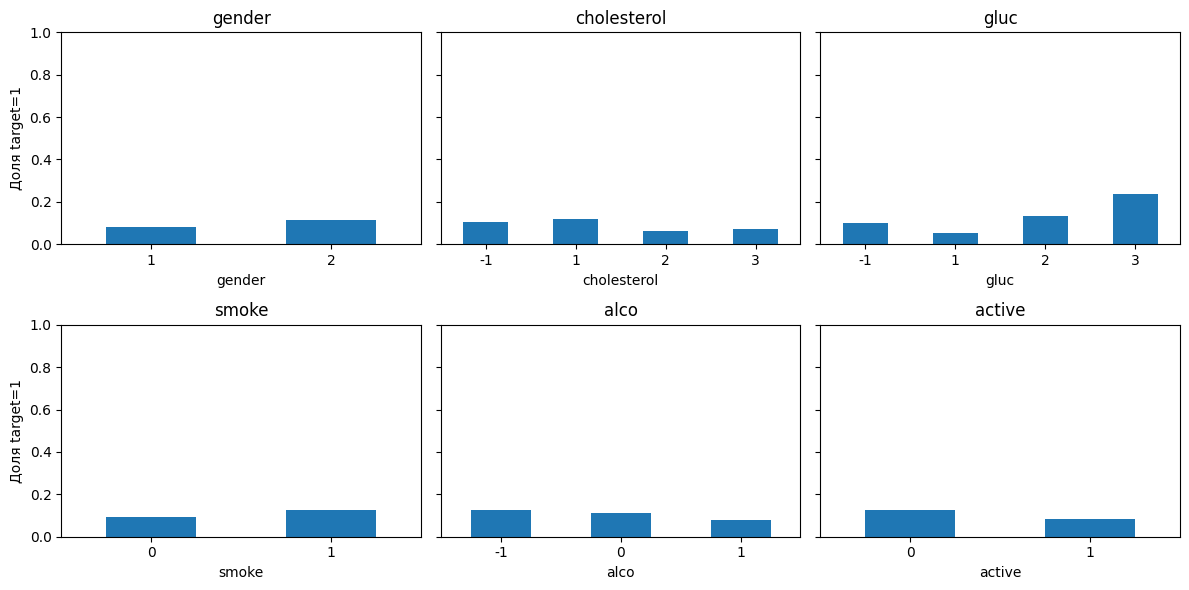

In [27]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharey=True)
for ax, column in zip(axes.flat, categorical):
    rate = train.groupby(column)['target'].mean()
    rate.plot.bar(ax=ax, title=column, ylim=(0, 1), ylabel='Доля target=1', rot=0)
plt.tight_layout()
plt.show()

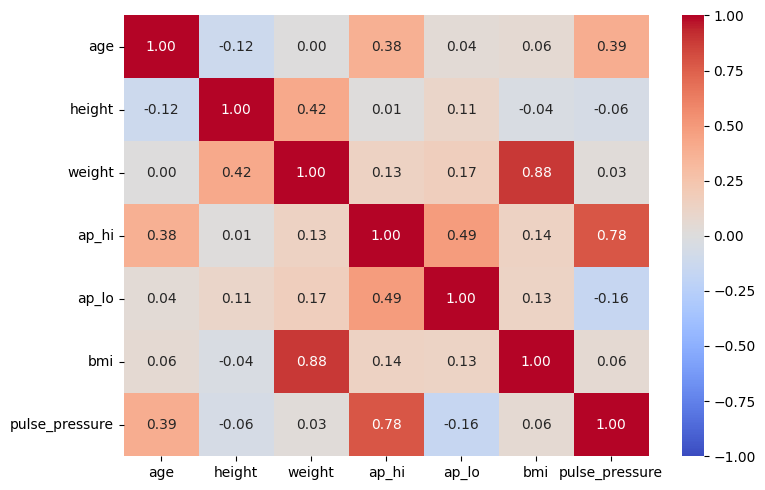

In [28]:
plt.figure(figsize=(8, 5))
sns.heatmap(X_train[numeric].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.tight_layout()
plt.show()

Классы несбалансированы: на train `target=1` составляет 9.87%. Возраст заметно отличается между классами: медиана около 65 лет при `target=1` против 47 лет при `target=0`. По росту различия почти отсутствуют. У веса и ИМТ правый хвост. При этом распределения сильно перекрываются.

Для верхнего давления медиана в классе 1 выше. У нижнего давления медиана приблизительно одинаковая. Возраст и давление выглядят информативнее роста и веса, но ни один отдельный признак не разделяет классы однозначно.

Категориальные признаки. Для `gluc` доля класса 1 растёт от категории 1 к категории 3 (примерно с 5.5% до 23.6% на train). Для `cholesterol`: в категориях 2 и 3 доля класса 1 ниже, чем в категории 1. Среди физически неактивных и курящих доля класса 1 выше; по `alco` видны необычное распределение значений и большая доля пропусков.

Выбросы. На boxplot заметны высокие значения веса, ИМТ и давления. Исключать их без дополнительной проверки не будем.

Корреляции. Самые сильные связи - между весом и ИМТ (0.88), верхним и пульсовым давлением (0.78), верхним и нижним давлением (0.49). Производные признаки частично повторяют информацию исходных; их реальную пользу проверим при обучении.


## 2. Обучение и сравнение

Сравним Logistic Regression, Random Forest, XGBoost, CatBoost, LightGBM, SVM, KNN и GaussianNB. Сначала все модели получают 11 исходных признаков и одинаковое разбиение.

Из-за дисбаланса классов основной критерий выбора - **Average Precision (AP)** на validation. Дополнительно смотрим ROC-AUC, Precision, Recall и F2. Метрики, зависящие от порога, пока рассчитываем при 0.5; рабочий порог подберём отдельно после выбора модели и признаков.


In [29]:
models = {
    'Logistic Regression': linear_model.LogisticRegression(max_iter=1500, random_state=SEED),
    'Random Forest': ensemble.RandomForestClassifier(
        n_estimators=300, max_depth=14, min_samples_leaf=15, n_jobs=2, random_state=SEED),
    'XGBoost': XGBClassifier(n_estimators=500, max_depth=3, learning_rate=0.05,
                            tree_method='hist', eval_metric='logloss', n_jobs=2, random_state=SEED),
    'CatBoost': CatBoostClassifier(iterations=500, depth=5, learning_rate=0.05,
                                  cat_features=tuple(categorical), thread_count=2, random_seed=SEED,
                                  verbose=False, allow_writing_files=False),
    'LightGBM': LGBMClassifier(n_estimators=500, num_leaves=15, learning_rate=0.05,
                              n_jobs=2, random_state=SEED, verbosity=-1),
    'Linear SVM': svm.LinearSVC(C=1.0, dual=False, max_iter=5000, random_state=SEED),
    'KNN': neighbors.KNeighborsClassifier(n_neighbors=35, n_jobs=2),
    'GaussianNB': naive_bayes.GaussianNB(),
}

In [30]:
groups = pd.util.hash_pandas_object(X_train[base_features], index=False)
splitter = model_selection.StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
svm_folds = list(splitter.split(X_train, y_train, groups))

In [31]:
def make_model(name, columns):
    numbers = [column for column in columns if column not in categorical]
    transformer = compose.ColumnTransformer([
        ('numeric', preprocessing.StandardScaler(), numbers),
        ('category', preprocessing.OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical),
    ], verbose_feature_names_out=False).set_output(transform='pandas')
    if name == 'CatBoost':
        transformer = 'passthrough'
    model = pipeline.Pipeline([('preprocess', transformer), ('model', base.clone(models[name]))])
    if name == 'Linear SVM':
        model = calibration.CalibratedClassifierCV(model, cv=svm_folds)
    return model

In [32]:
def evaluate(y_true, probability, threshold=0.5):
    predicted = np.asarray(probability) >= threshold

    return {
        'ROC_AUC': metrics.roc_auc_score(y_true, probability),
        'AP': metrics.average_precision_score(y_true, probability),
        'Recall': metrics.recall_score(y_true, predicted),
        'Precision': metrics.precision_score(
            y_true, predicted, zero_division=0
        ),
        'F2': metrics.fbeta_score(
            y_true, predicted, beta=2, zero_division=0
        ),
        'MCC': metrics.matthews_corrcoef(y_true, predicted),
        'Accuracy': metrics.accuracy_score(y_true, predicted),
    }

### MLflow

Для каждого запуска сохраняем набор признаков, параметры модели, seed, размеры выборок, AP и ROC-AUC на train, а также метрики validation. Это позволяет сравнивать модели и отслеживать результаты экспериментов.

После выбора лучшей модели дополним её эксперимент результатами test, выбранным порогом, графиками и сохранённой моделью с метаданными.


In [33]:
mlflow.set_tracking_uri('sqlite:///mlflow.db')
mlflow.set_experiment('heart-disease')
run_params = {
    'dataset': 'local/heart.csv', 'seed': SEED, 'split': 'group_random_70_15_15',
    'total_rows': len(data), **split_sizes,
}

In [34]:
def fit_candidate(name, columns, variant):
    model = make_model(name, columns)

    with mlflow.start_run(run_name=f'{name} | {variant}') as run:
        model.fit(X_train[columns], y_train)

        train_proba = model.predict_proba(X_train[columns])[:, 1]
        valid_proba = model.predict_proba(X_valid[columns])[:, 1]

        scores = evaluate(y_valid, valid_proba)

        train_ap = metrics.average_precision_score(y_train, train_proba)
        train_auc = metrics.roc_auc_score(y_train, train_proba)

        mlflow.log_params({
            **run_params,
            **models[name].get_params(),
            'features': columns,
            'variant': variant
        })

        mlflow.log_metrics({
            **{f'validation/{key}': value for key, value in scores.items()},
            'train/AP': train_ap,
            'train/ROC_AUC': train_auc
        })

        result = {
            'Model': name,
            'Variant': variant,
            'Train_AP': train_ap,
            'Train_ROC_AUC': train_auc,
            **scores
        }

    return model, run.info.run_id, result

In [35]:
fitted, run_ids, results = {}, {}, []

for name in models:
    fitted[name], run_ids[name], result = fit_candidate(name, base_features, 'base')
    results.append(result)

comparison = pd.DataFrame(results).drop(columns='Variant').set_index('Model')
comparison = comparison.sort_values('AP', ascending=False)
comparison.round(3)

,Train_AP,Train_ROC_AUC,ROC_AUC,AP,Recall,Precision,F2,MCC,Accuracy
Model,,,,,,,,,
CatBoost,0.490,0.863,0.816,0.298,0.065,0.481,0.079,0.151,0.906
XGBoost,0.454,0.864,0.814,0.293,0.060,0.436,0.073,0.135,0.905
Logistic Regression,0.327,0.822,0.815,0.287,0.055,0.449,0.067,0.132,0.905
Linear SVM,0.328,0.821,0.814,0.286,0.055,0.386,0.067,0.117,0.903
LightGBM,0.672,0.930,0.809,0.284,0.063,0.352,0.075,0.116,0.901
Random Forest,0.512,0.899,0.807,0.280,0.000,0.000,0.000,-0.005,0.906
KNN,0.345,0.848,0.778,0.242,0.015,0.462,0.019,0.070,0.906
GaussianNB,0.271,0.797,0.779,0.230,0.348,0.250,0.323,0.208,0.841


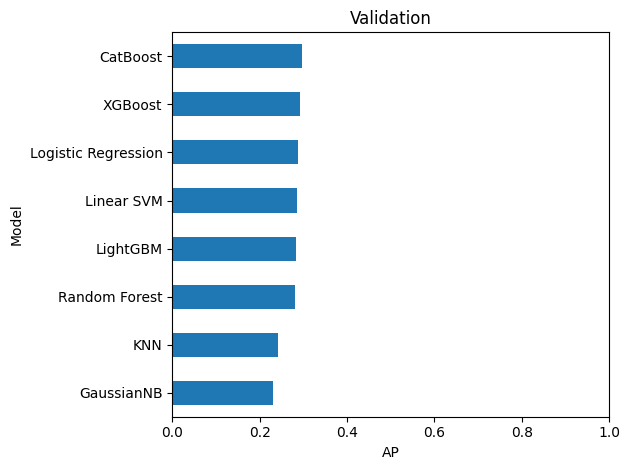

In [36]:
comparison.dropna(subset=['AP']).iloc[::-1].plot.barh(y='AP', legend=False, xlim=(0, 1), title='Validation')
plt.xlabel('AP')
plt.tight_layout()
plt.show()

## 3. Проверка дополнительных признаков

Для лидера сравним четыре набора: исходные признаки, `+BMI`, `+pulse` и `+both`. Параметры модели и разбиение оставляем одинаковыми, чтобы оценить вклад новых признаков.

Основная метрика сравнения - AP на validation. Исходные рост, вес и оба давления во всех вариантах сохраняем. Результаты этой проверки относятся только к выбранной модели.


In [37]:
best_name = comparison.index[0]
feature_sets = {
    'base': base_features,
    '+BMI': base_features + ['bmi'],
    '+pulse': base_features + ['pulse_pressure'],
    '+both': base_features + ['bmi', 'pulse_pressure'],
}
feature_models = {'base': fitted[best_name]}
feature_runs = {'base': run_ids[best_name]}
feature_results = [
    {'Variant': 'base', **comparison.loc[best_name].to_dict()}
]
for variant, columns in list(feature_sets.items())[1:]:
    feature_models[variant], feature_runs[variant], result = fit_candidate(best_name, columns, variant)
    feature_results.append({key: value for key, value in result.items() if key != 'Model'})
ablation = pd.DataFrame(feature_results).set_index('Variant')
ablation['Delta_AP'] = ablation['AP'] - ablation.loc['base', 'AP']
ablation.sort_values('AP', ascending=False).round(4)

,Train_AP,Train_ROC_AUC,ROC_AUC,AP,Recall,Precision,F2,MCC,Accuracy,Delta_AP
Variant,,,,,,,,,,
+BMI,0.4955,0.8638,0.8172,0.3022,0.0702,0.4590,0.0845,0.1512,0.9052,0.0042
base,0.4897,0.8631,0.8160,0.2980,0.0652,0.4815,0.0788,0.1508,0.9059,0.0000
+pulse,0.5018,0.8657,0.8176,0.2951,0.0627,0.4808,0.0758,0.1477,0.9059,-0.0028
+both,0.5096,0.8666,0.8160,0.2947,0.0627,0.4464,0.0757,0.1398,0.9050,-0.0032


Проверяем разницу AP на validation. Для CatBoost исходный набор дал AP = 0.2980, `+BMI` - 0.3022, `+pulse` - 0.2951, `+both` - 0.2947.

Максимальный AP получен с ИМТ, поэтому выбираем `+BMI` (12 признаков). Выигрыш относительно исходного набора небольшой - около 0.0042 AP, и его устойчивость на других разбиениях отдельно не проверялась.

Ниже посмотрим permutation importance по снижению **AP** на validation.


In [38]:
best_variant = ablation['AP'].idxmax()

features = feature_sets[best_variant]
best_model = feature_models[best_variant]
best_run = feature_runs[best_variant]

pd.Series({
    'Модель': best_name,
    'Признаки': best_variant,
    'Количество': len(features),
    'Validation AP': ablation.loc[best_variant, 'AP']
})

Модель           CatBoost
Признаки             +BMI
Количество             12
Validation AP    0.302154
dtype: object

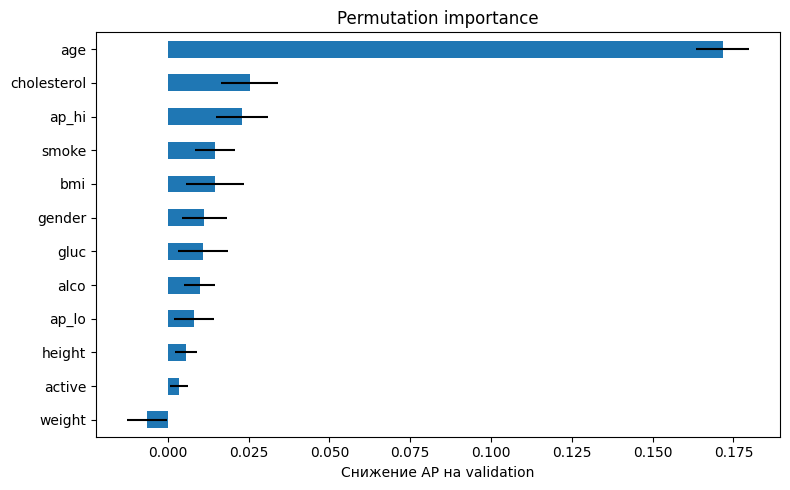

In [39]:
sample = X_valid[features].sample(2000, random_state=SEED)
permutation = inspection.permutation_importance(
    best_model, sample, y_valid.loc[sample.index],
    scoring='average_precision', n_repeats=5, random_state=SEED)
importance = pd.DataFrame({'mean': permutation.importances_mean, 'std': permutation.importances_std},
                          index=features).sort_values('mean')
ax = importance['mean'].plot.barh(xerr=importance['std'], figsize=(8, 5))
ax.set(xlabel='Снижение AP на validation', title='Permutation importance')
importance_figure = ax.figure
plt.tight_layout()
plt.show()

## 4. Порог и финальная проверка

Модель и признаки выбраны: CatBoost с дополнительным ИМТ. Порог 0.5 даёт слишком низкий Recall, поэтому подберём его на validation.

Переберём пороги от 0.01 до 0.5 и выберем максимальный MCC при условии `Recall >= 0.65`. MCC учитывает все четыре исхода классификации; ограничение на Recall не позволяет выбрать порог, пропускающий слишком много положительных случаев. Значение 0.65 - исследовательское, а не клиническое требование.

На validation выбран порог около 0.092: Precision = 0.215, Recall = 0.799, F2 = 0.518, MCC = 0.304. Положительный прогноз получают около 34.9% наблюдений. Далее проверим зафиксированный порог на test.


In [40]:
valid_probability = best_model.predict_proba(
    X_valid[features]
)[:, 1]

rows = []

for t in np.linspace(0.01, 0.5, 300):
    pred = (valid_probability >= t).astype(int)

    rows.append({
        'Threshold': t,
        'Precision': metrics.precision_score(
            y_valid, pred, zero_division=0
        ),
        'Recall': metrics.recall_score(y_valid, pred),
        'F2': metrics.fbeta_score(
            y_valid, pred, beta=2, zero_division=0
        ),
        'MCC': metrics.matthews_corrcoef(y_valid, pred),
        'Positive_rate': pred.mean()
    })

threshold_results = pd.DataFrame(rows)

MIN_RECALL = 0.65

candidates = threshold_results[
    threshold_results['Recall'] >= MIN_RECALL
]

best_row = candidates.sort_values(
    'MCC', ascending=False
).iloc[0]

threshold = float(best_row['Threshold'])

display(best_row.round(3))

Threshold        0.092
Precision        0.215
Recall           0.799
F2               0.518
MCC              0.304
Positive_rate    0.349
Name: 50, dtype: float64

ROC_AUC      0.803
AP           0.306
Recall       0.752
Precision    0.219
F2           0.505
MCC          0.292
Accuracy     0.719
dtype: float64

TP                               309.00000
FP                              1105.00000
TN                              2776.00000
FN                               102.00000
Доля положительных прогнозов       0.32945
dtype: float64

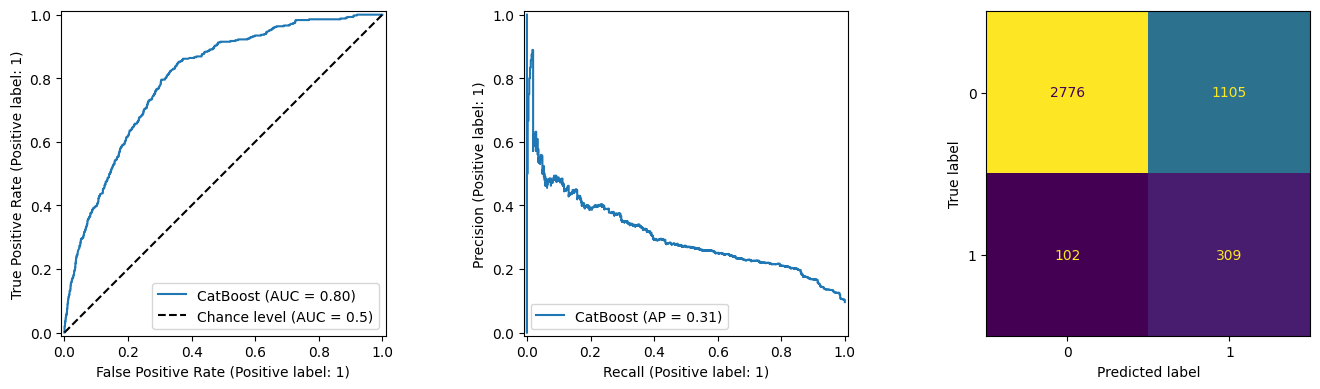

In [41]:
test_probability = best_model.predict_proba(
    X_test[features]
)[:, 1]

test_metrics = evaluate(
    y_test, test_probability, threshold=threshold
)

display(pd.Series(test_metrics).round(3))

test_predicted = (test_probability >= threshold).astype(int)

tn, fp, fn, tp = metrics.confusion_matrix(
    y_test, test_predicted
).ravel()

display(pd.Series({
    'TP': tp,
    'FP': fp,
    'TN': tn,
    'FN': fn,
    'Доля положительных прогнозов': test_predicted.mean()
}))

test_figure, axes = plt.subplots(1, 3, figsize=(14, 4))

metrics.RocCurveDisplay.from_predictions(
    y_test, test_probability,
    name=best_name, ax=axes[0],
    plot_chance_level=True
)

metrics.PrecisionRecallDisplay.from_predictions(
    y_test, test_probability,
    name=best_name, ax=axes[1]
)

metrics.ConfusionMatrixDisplay.from_predictions(
    y_test, test_predicted,
    ax=axes[2], colorbar=False
)

plt.tight_layout()
plt.show()

## 5. Сохранение

Сохраняем выбранную модель и метаданные: название, список признаков, порог классификации, значения для заполнения пропусков и правила создания дополнительных признаков. Результаты экспериментов и графики записываем в MLflow.

Предобработка исходных данных выполняется отдельно от сохранённой модели. Поэтому для применения к новым данным необходимо воспроизвести преобразования на основе сохранённых метаданных.

API получает возраст в годах, использует сохранённые значения заполнения и переводит категории в строки, как при обучении. В ответ также передаются test-метрики: score трактуем как оценку модели, а не персональный медицинский риск.


In [42]:
from pathlib import Path

Path('../models').mkdir(parents=True, exist_ok=True)

metadata = {
    'schema_version': 2,
    'input_age_unit': 'years',
    'model': best_name,
    'threshold': float(threshold),
    'features': features,
    'test_metrics': {k: float(v) for k, v in test_metrics.items()},
    'test_prevalence': float(y_test.mean()),
    'dataset_rows': len(raw),
    'threshold_policy': 'max_mcc_with_min_recall',
    'min_recall_valid': MIN_RECALL,

    'medians': {k: float(v) for k, v in medians.items()},
    'modes': {k: int(v) for k, v in modes.items()},
    'unknown_columns': unknown_fill,
    'unknown_value': -1,
    'categorical_columns': cat_cols,

    'age_divisor': 365.25,
    'derived_features': {
        'bmi': 'weight / (height / 100) ** 2',
        'pulse_pressure': 'ap_hi - ap_lo'
    }
}

joblib.dump(best_model, '../models/model.joblib', compress=3)

with open('../models/meta.json', 'w', encoding='utf-8') as file:
    json.dump(metadata, file, ensure_ascii=False, indent=2)

In [43]:
with mlflow.start_run(run_id=best_run):
    mlflow.set_tag('selected', 'true')
    mlflow.log_params({
        'threshold': threshold,
        'threshold_policy': 'max_mcc_with_min_recall',
        'min_recall_valid': MIN_RECALL,
        'feature_selection_metric': 'AP'
    })
    mlflow.log_metrics({f'test/{key}': value for key, value in test_metrics.items()})
    mlflow.log_dict(comparison.dropna(subset=['AP']).to_dict('index'), 'comparison.json')
    mlflow.log_dict(ablation.to_dict('index'), 'feature_comparison.json')
    mlflow.log_figure(test_figure, 'test_curves.png')
    mlflow.log_figure(importance_figure, 'importance.png')
    mlflow.log_artifacts('../models', artifact_path='model')
    requirements_file = Path('../requirements.txt')
    if requirements_file.is_file():
        mlflow.log_artifact(str(requirements_file), artifact_path='source')

    notebook_file = Path('heart.ipynb')
    if notebook_file.is_file():
        mlflow.log_artifact(str(notebook_file), artifact_path='source')

# **ВЫВОДЫ:**

1) В датасете 28 270 наблюдений и выраженный дисбаланс: около 9.75% имеют `cardio=1`. Обнаружено 30 878 пропущенных значений. Для числовых признаков использована медиана, для `smoke` и `active` - мода, для `alco`, `cholesterol`, `gluc` - отдельная категория неизвестных значений. Статистики заполнения рассчитаны по train.

2) По EDA наиболее заметные различия между классами связаны с возрастом, верхним давлением и HbA1c. Для холестерина наблюдается нетипичная зависимость: доля положительного класса в категориях 2 и 3 ниже, чем в категории 1. Распределения сильно перекрываются, поэтому по отдельным признакам надёжно разделить классы не удаётся.

3) Среди базовых моделей по AP на validation выбрана CatBoost (AP = 0.298). Добавление ИМТ увеличило AP до 0.302; пульсовое давление и добавление обоих признаков улучшения не дали. В итоге использованы 12 признаков.

4) Порог подобран на validation по максимуму MCC при ограничении `Recall >= 0.65`. Получено значение около 0.092. На test: ROC-AUC = 0.803, AP = 0.306, Recall = 0.752, Precision = 0.219, F2 = 0.505. Из 411 положительных случаев обнаружено 309, пропущено 102. При этом 1 105 положительных прогнозов оказались ложными, а всего модель отметила 32.9% пациентов.
